## steps to construct the process

1. load the dataset
2. data incpetion (head, tail, size , shape, info, describe)
3. Data validation (new columns(combine the multiple columns into the single columns))
4. Data processing (null values, outliers, missing values, duplicates )
5. Data splitting (train the splitter)
6. importing the model(regression, classification, reforicement )
7. Model fitting 
8. model predict 
9. Model Evaluation
10. imporving model / changing weights 

## Importing libaries

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv(r'C:\Users\mrudu\OneDrive\Desktop\salary(ml)\SelfPracticeSalary_Data.csv')

## Data Incpetion

In [ ]:
df.head(2)

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0


In [ ]:
df.tail(2)

,YearsExperience,Salary
28,10.3,122391.0
29,10.5,121872.0


In [ ]:
df.size

60

In [ ]:
df.shape[1]

2

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes


In [ ]:
df.describe()

,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


C:\Users\mrudu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\seaborn\axisgrid.py:2100: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


<Figure size 1200x600 with 0 Axes>

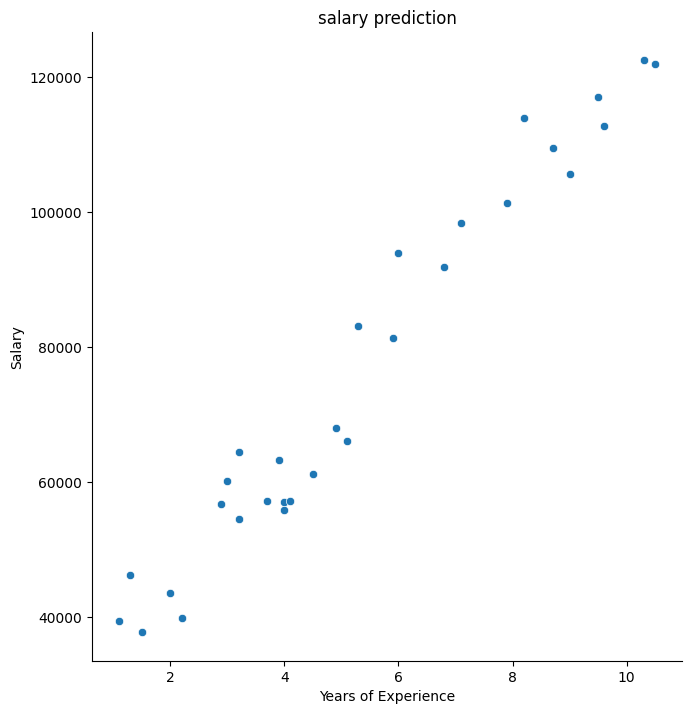

In [ ]:
# These plots hepls to explain the values and how they are scattered in the dataset.

plt.figure(figsize=(12,6))
sns.pairplot(df, x_vars=['YearsExperience'],
             y_vars=['Salary'], size=7,kind='scatter')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.title('salary prediction')    
plt.show()         

In [ ]:
# cooking the data

x= df['YearsExperience']
x.head()

0    1.1
1    1.3
2    1.5
3    2.0
4    2.2
Name: YearsExperience, dtype: float64

In [ ]:
# cooking the data 

y= df['Salary']
y.head()

0    39343.0
1    46205.0
2    37731.0
3    43525.0
4    39891.0
Name: Salary, dtype: float64

In [ ]:
# Import the segragation data from scikit library

from sklearn.model_selection import train_test_split

In [ ]:
# split the data for train and test

x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.7, random_state=100)

In [ ]:
print(len(x))

30


In [ ]:
x_train = x_train.to_numpy().reshape(-1, 1)
x_test = x_test.to_numpy().reshape(-1, 1)

In [ ]:
# importing linear regression model from scikeit learn

from sklearn.linear_model import LinearRegression

In [ ]:
# Fitting the model

lr = LinearRegression()
lr.fit(x_train,y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [ ]:
# Predicting the salary for the test values

y_pred = lr.predict(x_test)

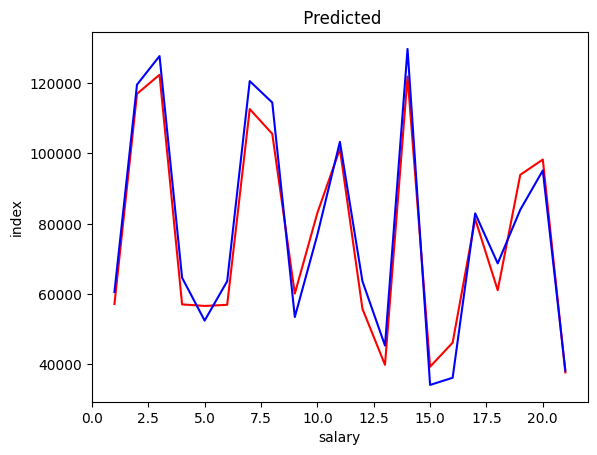

In [ ]:
# plotting the actual and predicted values

c = [i for i in range(1,len(y_test)+1,1)]
plt.plot(c,y_test,color='r',linestyle='-')
plt.plot(c,y_pred,color='b',linestyle='-')
plt.xlabel('salary')
plt.ylabel('index')    
plt.title(' Predicted')
plt.show()

In [ ]:
#Importing metrices for the evaluation of the model

from sklearn.metrics import r2_score,mean_squared_error


In [ ]:
# calculate mean square error
mse = mean_squared_error(y_test,y_pred)
mse

40288474.904821776

In [ ]:
# calculate R square value

rsq = r2_score(y_test,y_pred)
rsq

0.9502759065040127